# 05 · 多级库存智能协同 —— 最终演示（final demo）

> 赛题二 · 方向二 ｜ 三层供应链网络：**区域仓 → 城市仓 → 终端门店**
> 仿真框架：[DeepBullwhip 0.4.1](https://pypi.org/project/deepbullwhip/)（pip 安装）
> 本次实验数据来源：合成 AR(1)（seed=42 可复现）；M5 加载路径已实现，本次未启用。

## 一句话方案

下级节点只向上级上报**聚合后的需求缺口指标**（缺口总量 + 置信区间），不上报原始订单明细；
上级节点据此在下单量上叠加一个补偿项，把"预测驱动的补货"变成"信号驱动的补货"。

```
      需求与预测层                              拓扑与协同层
  合成 AR(1) ──> 长表 ──> WeightedMA ──┐   ┌── 聚合缺口信号 SignalBus
                                       ├──>┤
                        *(mean, std) 矩阵 └──  OrderUpTo + alpha × 补偿项
                                                          │
                                                          v
                                     NetworkSupplyChain.simulate()
                                                          │
                                                          v
                              Bullwhip Ratio / Fill Rate / Total Cost
```

## 演示流程

| # | 章节 | 看点 |
|---|---|---|
| 1 | 需求加载与预测 | mean + std 二元输出；预测不确定性来自历史残差 |
| 2 | 网络拓扑 | 7 节点 / 6 边，方向为"区域仓 → 城市仓 → 门店" |
| 3 | 基线策略 | OrderUpTo 暴露中间层缺货、牛鞭逐级放大 |
| 4 | 协同策略 | 聚合缺口信号 + alpha 扫描，找到相变临界 |
| 5 | 基线 / 协同对比 | 总成本 **-26.5%**，可优化层 fill rate **+36.7pp** |
| 6 | 一键入口 | `agent_wrapper` 单函数跑通全链路 |

## 0 · 环境准备

统一从这里设置项目根、导入依赖、确定产物目录。

In [1]:
import sys
from pathlib import Path

# notebook 可能在 notebooks/ 下或项目根下启动，两种都兜住
_root = Path.cwd()
if _root.name == "notebooks":
    _root = _root.parent
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

get_ipython().run_line_magic("matplotlib", "inline")   # 图内嵌展示（nbconvert 执行同样生效）

# --- 需求、预测与预测可视化 ---
from src.data_loader import pivot_demand_wide
from src.forecasting.baseline_forecasters import (
    generate_baseline_forecasts, run_baseline_comparison, save_baseline_metrics,
)
from src.forecasting.custom_forecaster import (
    WeightedMAForecaster, run_comparison_with_custom,
)
from src.visualization.dashboard import (
    FIGURES_DIR,
    plot_demand_overview, plot_forecast_mean, plot_uncertainty_band,
    plot_summary_dashboard, plot_bullwhip_amplification, plot_node_cost_comparison,
)
# --- 拓扑与仿真执行 ---
from src.network.topology import (
    build_network_from_config, build_coordinated_network_from_config,
    run_baseline_policy,
)
from src.simulation.run_benchmark import run_comparison
# --- 全流程封装 ---
from agent.agent_wrapper import (
    prepare_demand, build_forecast_bundle, run_network_simulation,
)

CONFIG_PATH = _root / "config" / "network_config.yaml"
RESULTS_DIR = _root / "outputs" / "results"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 140)

print(f"python  : {sys.executable}")
print(f"project : {_root}")
print(f"config  : {CONFIG_PATH}")

python  : d:\Users\21264\Desktop\黑客淞\a\supply-chain-agent\.venv\Scripts\python.exe
project : D:\Users\21264\Desktop\黑客淞\a\supply-chain-agent
config  : D:\Users\21264\Desktop\黑客淞\a\supply-chain-agent\config\network_config.yaml


---

## 1 · 需求侧（A）：加载、清洗、预测

### 1.1 需求加载

`agent_wrapper.prepare_demand()` 封装了三级降级：

```
M5 本地 CSV（data/raw/m5/sales_train_evaluation.csv）
        v 取不到
Kaggle 自动下载（缓存 ~/.deepbullwhip/data/m5/）
        v 取不到
合成 AR(1)（seed 可复现）—— 本 notebook 走这条，保证离线可跑
```

三条路径产出**同一张长表**：`[date, store_id, item_id, demand]`，
下游（预测、拓扑映射、仿真）完全不感知数据来源差异。

In [2]:
# 合成兜底路径：4 条序列 → 4 个终端门店，对齐 config/network_config.yaml（sku_count=4 / simulation_days=365）
bundle = prepare_demand(use_m5=False, n_nodes=4, n_days=365, seed=42)

print(bundle.summary())
print()
print("长表前 4 行：")
print(bundle.demand_df.head(4).to_string(index=False))
print()
print("各序列需求水平：")
print(bundle.demand_df.groupby(["store_id", "item_id"])["demand"]
      .agg(["mean", "std"]).round(3).to_string())

[agent] [合成] 使用框架 AR(1) 合成需求（seed 可复现）
DemandBundle(source='synthetic AR(1)', shape=(1460, 4), nodes=4)

长表前 4 行：
      date store_id item_id  demand
2024-01-01      SYN   SKU_1    10.0
2024-01-01      SYN   SKU_2    10.0
2024-01-01      SYN   SKU_3    10.0
2024-01-01      SYN   SKU_4    10.0

各序列需求水平：
                    mean    std
store_id item_id               
SYN      SKU_1     9.945  2.816
         SKU_2    10.061  2.752
         SKU_3    10.262  3.043
         SKU_4    10.037  2.883


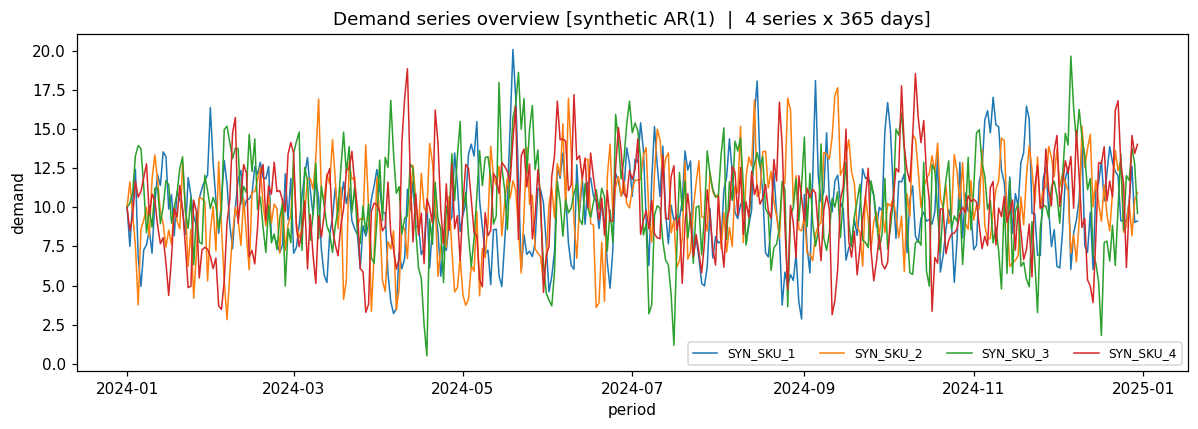

In [3]:
fig = plot_demand_overview(
    bundle.demand_df,
    data_source="synthetic AR(1)  |  4 series x 365 days",
    save_path=FIGURES_DIR / "fig_demo_demand_overview.png",
)
plt.show()

### 1.2 预测输出契约：`(mean, std)` 二元输出

**这是 A→B 的冻结接口**（详见 `docs/AB_interface_checklist.md` §3.2）：

| 项 | 约定 |
|---|---|
| 单点接口 | `Forecaster.forecast(history, steps_ahead=1) -> tuple[float, float]`（框架抽象签名，返回**标量**） |
| 整段接口 | `forecaster.generate_forecasts(demand) -> (fm, fs)`，两个数组形状均为 `(T,)` |
| `std` 来源 | **历史残差的经验标准差**（"1 步加权预测 vs 真实值"滚动残差，ddof=1），**不是写死的常数** |
| 边界 | `fs` 允许为 0（历史不足 2 期时的启动瞬态），消费侧不得假设 `fs > 0` |

自定义预测器 `WeightedMAForecaster`：`mean` = 最近 `window` 期加权平均；
`std` = 滚动残差样本标准差。下面把它和三个官方基线放在同一张表里比。

In [4]:
wide = pivot_demand_wide(bundle.demand_df)          # 长表 -> 宽表（index=date, columns=SYN_SKU_i）
print(f"宽表 {wide.shape}：{list(wide.columns)}")

# 与 run_benchmark 保持同一预测口径：window=8 + 递增权重
DEMO_WMA = dict(window=8, weights=[1, 1, 1, 1, 2, 2, 3, 4])

metrics = run_comparison_with_custom(
    wide, forecaster=WeightedMAForecaster(**DEMO_WMA), name="WeightedMA",
)
save_baseline_metrics(metrics, "baseline_metrics_with_custom.csv")

print("\n预测误差对比（3 基线 + 1 自研）：")
print(metrics.round(4).reset_index().to_string(index=False))

宽表 (365, 4)：['SYN_SKU_1', 'SYN_SKU_2', 'SYN_SKU_3', 'SYN_SKU_4']



预测误差对比（3 基线 + 1 自研）：
          forecaster    MAE   RMSE    MAPE
               Naive 2.2608 2.8561 28.2696
       MovingAverage 2.0898 2.6436 25.7404
ExponentialSmoothing 1.4825 1.8647 17.9446
          WeightedMA 1.5882 1.9940 19.2419


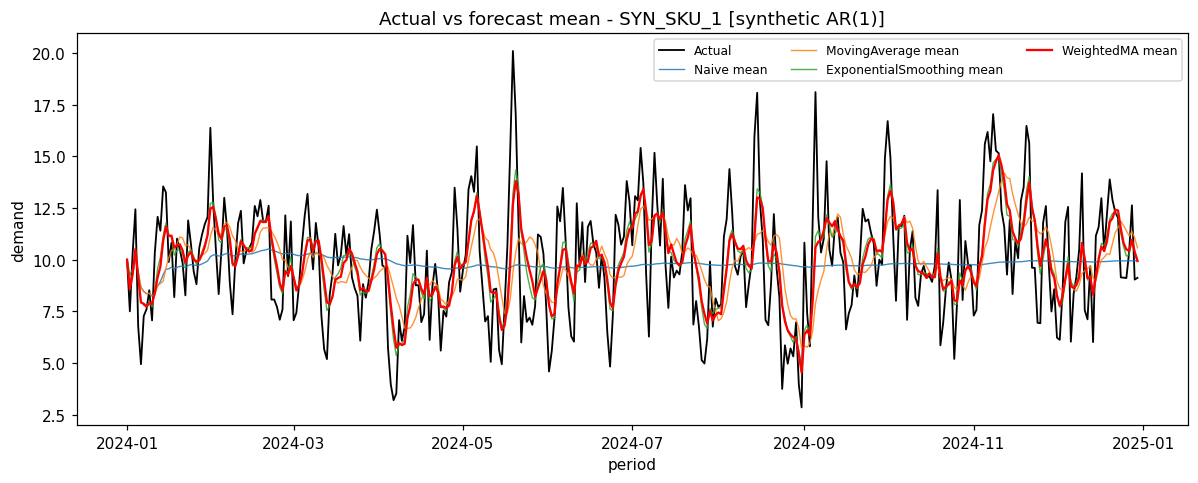

In [5]:
col = wide.columns[0]

base_fc = generate_baseline_forecasts(wide)         # {列名: {预测器名: (fm, fs)}}
wma_fm, wma_fs = WeightedMAForecaster(**DEMO_WMA).generate_forecasts(wide[col])

forecast_map = dict(base_fc[col])
forecast_map["WeightedMA"] = (wma_fm, wma_fs)

fig = plot_forecast_mean(
    wide, col, forecast_map,
    data_source="synthetic AR(1)",
    save_path=FIGURES_DIR / "fig1_baseline_vs_custom_mean.png",
)
plt.show()

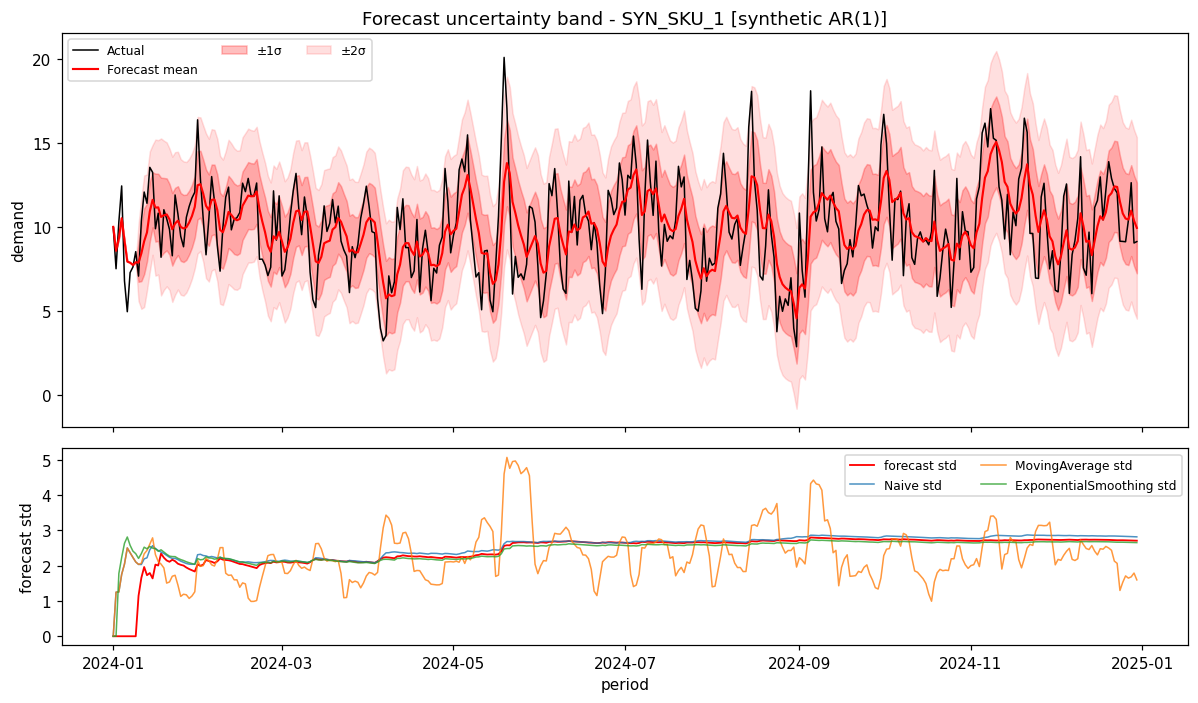

In [6]:
# std(t) 对比：自研预测器的不确定性来自残差，随历史长度收敛
std_curves = {name: fs for name, (_fm, fs) in base_fc[col].items()}

fig = plot_uncertainty_band(
    wide, col, wma_fm, wma_fs,
    std_curves=std_curves,
    sigmas=(1, 2),
    data_source="synthetic AR(1)",
    save_path=FIGURES_DIR / "fig2_forecast_uncertainty_band.png",
)
plt.show()

---

## 2 · 网络拓扑

配置来自 `config/network_config.yaml`：1 区域仓 → 2 城市仓 → 4 终端门店。

> **实测要点**（`docs/AB_interface_checklist.md` §1.7）：
> 补货提前期配在**节点**上（`EchelonConfig.lead_time`），配在边上（`EdgeConfig.lead_time`）不生效。

In [7]:
net = build_network_from_config(CONFIG_PATH)

print(f"节点数 {len(net.graph.nodes)}   边数 {len(net.graph.edges)}")
print(f"拓扑序 {net.graph.topological_order()}")
print()
print("上下游连接关系：")
for src, dst in net.graph.edges:
    print(f"  {src:22s} -> {dst}")

节点数 7   边数 6
拓扑序 ['regional_warehouse', 'city_warehouse_1', 'city_warehouse_2', 'store_1', 'store_2', 'store_3', 'store_4']

上下游连接关系：
  regional_warehouse     -> city_warehouse_1
  city_warehouse_1       -> store_1
  city_warehouse_1       -> store_2
  regional_warehouse     -> city_warehouse_2
  city_warehouse_2       -> store_3
  city_warehouse_2       -> store_4


---

## 3 · 基线策略（OrderUpTo）：问题暴露

用框架默认的 `OrderUpToPolicy` 各节点独立决策，需求与预测只喂给**叶子门店**
（框架内部对中间节点用"最近 8 期下游订单均值"顶替，见对齐清单 §1.4）。

**要观察的两件事**：

1. 中间层（城市仓 / 区域仓）的库存均值是否长期为负 —— 即补货跟不上下游订单；
2. 牛鞭系数是否逐级放大（城市仓 > 门店）。

In [8]:
STORE_NAMES = ["store_1", "store_2", "store_3", "store_4"]

# 门店需求 + 预测（喂给叶子节点）
demand, fm, fs = {}, {}, {}
for store, colname in zip(STORE_NAMES, wide.columns[:len(STORE_NAMES)]):
    s = wide[colname].to_numpy(dtype=np.float64)
    m, d = WeightedMAForecaster(**DEMO_WMA).generate_forecasts(s)
    demand[store], fm[store], fs[store] = s, m, d

print(f"预测交接物就绪：{len(demand)} 个门店，T = {len(demand['store_1'])}")
print("  " + "  ".join(f"{k}: fm{fm[k].shape} fs{fs[k].shape}" for k in STORE_NAMES))

预测交接物就绪：4 个门店，T = 365
  store_1: fm(365,) fs(365,)  store_2: fm(365,) fs(365,)  store_3: fm(365,) fs(365,)  store_4: fm(365,) fs(365,)


In [9]:
net_base = build_network_from_config(CONFIG_PATH)
res_base = run_baseline_policy(net_base, demand, fm, fs)

rows = [
    {"node": name,
     "orders_mean": float(np.mean(r.orders)),
     "inv_mean": float(np.mean(r.inventory_levels)),
     "bullwhip": float(r.bullwhip_ratio),
     "cost": float(r.total_cost),
     "framework_fill_rate": float(r.fill_rate)}
    for name, r in res_base.node_results.items()
]
print(pd.DataFrame(rows).round(3).to_string(index=False))
print()
print(f"总成本 {res_base.total_cost:,.2f}   累计牛鞭系数 {res_base.cumulative_bullwhip:.4f}")
print()
print("观察：城市仓 / 区域仓的 inv_mean 长期为负 —— 中间层持续缺货；")
print("      牛鞭系数从门店(1.4~1.6)放大到城市仓(4.7~5.6)，符合牛鞭效应的预期。")

              node  orders_mean  inv_mean  bullwhip      cost  framework_fill_rate
regional_warehouse       39.911   -81.604     4.483 12079.057                0.036
  city_warehouse_1       19.737   -21.879     4.660  4192.389                0.047
           store_1        9.854     5.915     1.518   477.402                0.923
           store_2        9.967     6.160     1.368   474.337                0.942
  city_warehouse_2       20.058   -22.585     5.551  4359.848                0.063
           store_3       10.180     6.099     1.640   475.837                0.926
           store_4        9.949     6.368     1.540   505.053                0.926

总成本 22,563.92   累计牛鞭系数 4.4828

观察：城市仓 / 区域仓的 inv_mean 长期为负 —— 中间层持续缺货；
      牛鞭系数从门店(1.4~1.6)放大到城市仓(4.7~5.6)，符合牛鞭效应的预期。


---

## 4 · 协同策略：聚合缺口信号 + alpha 扫描

协同形式（`src/coordination/`）：

```
order = OrderUpTo 基线下单量  +  alpha × 下游聚合缺口
```

* `alpha = 0` → 退化为纯 OrderUpTo，**且总成本应与基线完全一致**（一致性自检）；
* `alpha` 增大 → 协同增强，成本下降；
* `alpha` 过大 → 系统振荡，成本反弹（相变临界）。

下面是 alpha 扫描，同时输出**两个 fill rate 口径**：

| 口径 | 定义 | 用途 |
|---|---|---|
| `framework_fill_rate` | 框架自带：库存非负的期数占比 | ⚠️ 非真实订单满足率，见对齐清单 §1.6 |
| `true_fill_rate` | 自研：`1 - 缺货量 / 需求量`，含区域仓 | 区域仓恒低（顶层无上游供应商，框架不计补货） |
| `true_fill_rate_excl_top` | 自研：同上但**排除区域仓** | **对外主口径** —— 协同策略实际作用的层级 |

In [10]:
ALPHAS = (0.0, 0.3, 0.5, 0.8, 1.0)

bench = run_comparison(CONFIG_PATH, demand, fm, fs, alphas=ALPHAS)

print("=== 系统级指标对比 ===")
print(bench.summary_df.round(4).to_string(index=False))

=== 系统级指标对比 ===
      policy  alpha  total_cost  cumulative_bullwhip  framework_fill_rate  true_fill_rate  true_fill_rate_excl_top
    baseline    NaN  22563.9238               4.4828               0.5519          0.0000                   0.4170
coord(a=0.0)    0.0  22563.9238               4.4828               0.5519          0.0000                   0.4170
coord(a=0.3)    0.3  19447.4593               4.6489               0.5620          0.0784                   0.5599
coord(a=0.5)    0.5  17914.1099               4.8406               0.5734          0.1524                   0.6522
coord(a=0.8)    0.8  16576.4380               5.0290               0.6102          0.2123                   0.7842
coord(a=1.0)    1.0  16040.3661               4.4626               0.7843          0.2729                   0.9811


In [11]:
MID_NODES = ["city_warehouse_1", "city_warehouse_2"]

mid = bench.node_metrics_df[bench.node_metrics_df["node"].isin(MID_NODES)]
print("=== 城市仓（协同策略实际作用的层级）===")
print(mid.round(3).to_string(index=False))

print()
print("=== 区域仓（顶层，受框架限制，fill rate 恒低）===")
top = bench.node_metrics_df[bench.node_metrics_df["node"] == "regional_warehouse"]
print(top.round(3).to_string(index=False))

=== 城市仓（协同策略实际作用的层级）===
      policy             node  orders_mean  inv_mean  bullwhip     cost  true_fill_rate
    baseline city_warehouse_1       19.737   -21.879     4.660 4192.389           0.000
    baseline city_warehouse_2       20.058   -22.585     5.551 4359.848           0.000
coord(a=0.0) city_warehouse_1       19.737   -21.879     4.660 4192.389           0.000
coord(a=0.0) city_warehouse_2       20.058   -22.585     5.551 4359.848           0.000
coord(a=0.3) city_warehouse_1       19.752   -15.924     4.272 3160.559           0.143
coord(a=0.3) city_warehouse_2       20.080   -16.569     5.159 3324.915           0.114
coord(a=0.5) city_warehouse_1       19.763   -11.930     4.143 2511.546           0.327
coord(a=0.5) city_warehouse_2       20.094   -12.558     5.110 2654.552           0.300
coord(a=0.8) city_warehouse_1       19.778    -5.800     4.068 1636.226           0.585
coord(a=0.8) city_warehouse_2       20.115    -6.267     5.098 1698.020           0.573
coord(a=

---

## 5 · 基线 / 协同对比结果

三张对比图（仿真对比绘图函数），并落盘为路演素材：

* `fig_benchmark_summary.png` —— 总成本 / 牛鞭 / fill rate 的总览；
* `fig_bullwhip_amplification.png` —— 牛鞭系数沿供应链层级的放大；
* `fig_node_cost_comparison.png` —— 节点级成本对比。

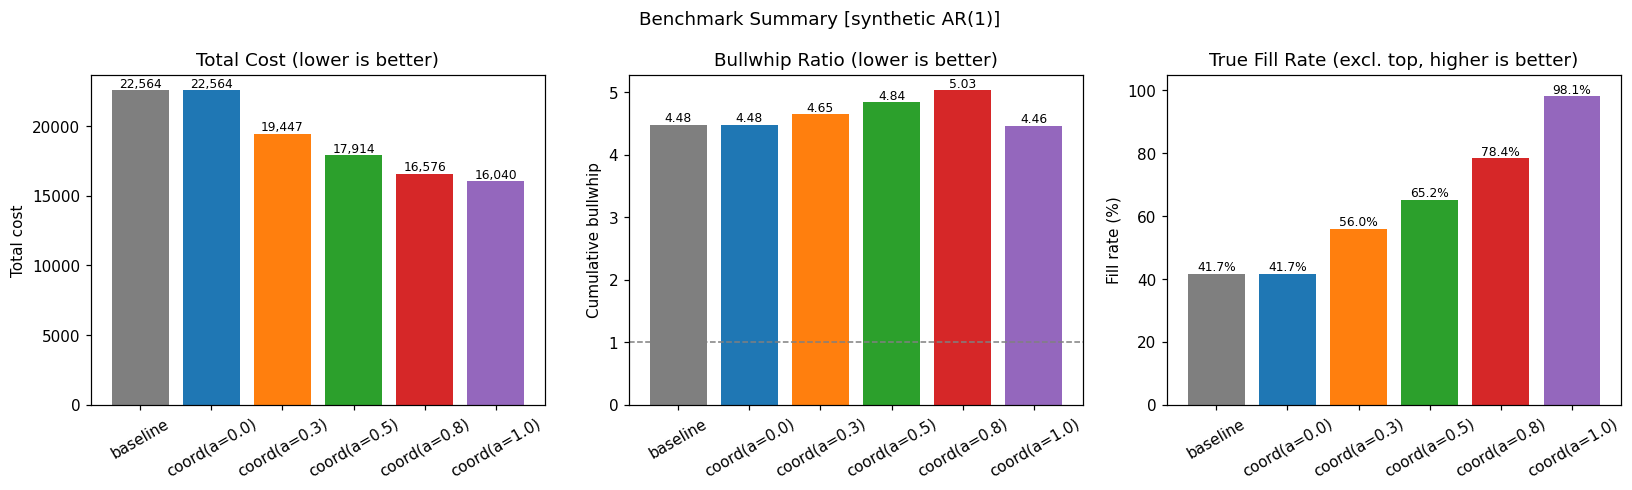

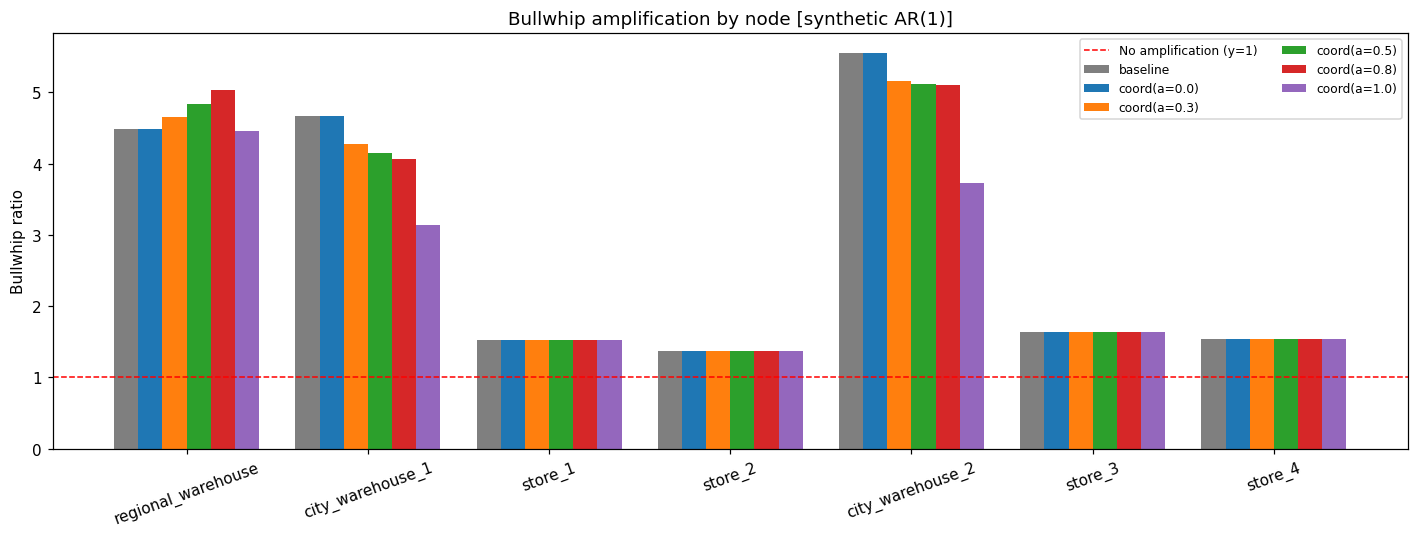

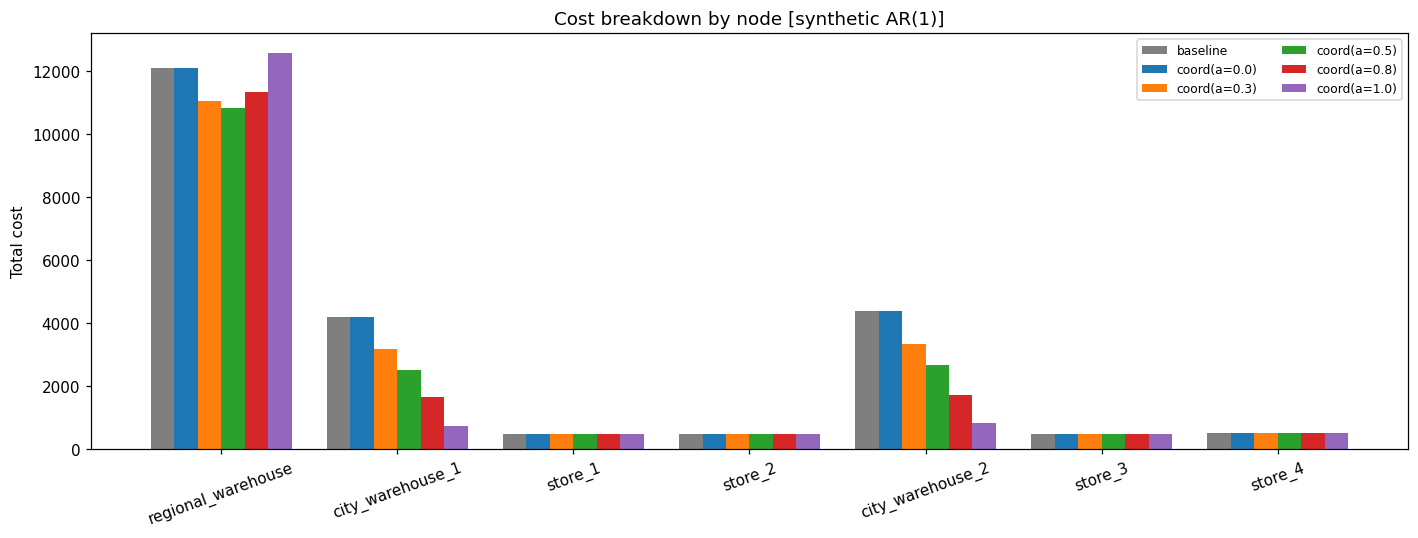

In [12]:
plot_summary_dashboard(bench, data_source="synthetic AR(1)",
                       save_path=FIGURES_DIR / "fig_benchmark_summary.png")
plot_bullwhip_amplification(bench, data_source="synthetic AR(1)",
                            save_path=FIGURES_DIR / "fig_bullwhip_amplification.png")
plot_node_cost_comparison(bench, data_source="synthetic AR(1)",
                          save_path=FIGURES_DIR / "fig_node_cost_comparison.png")
plt.show()

In [13]:
# 关键数字从 benchmark 结果里现取现算，避免文档与产物漂移
ref = "coord(a=0.8)"
b_row = bench.summary_df[bench.summary_df["policy"] == "baseline"].iloc[0]
c_row = bench.summary_df[bench.summary_df["policy"] == ref].iloc[0]

delta_cost = (c_row["total_cost"] / b_row["total_cost"] - 1) * 100
delta_fill = (c_row["true_fill_rate_excl_top"] - b_row["true_fill_rate_excl_top"]) * 100

summary = pd.DataFrame({
    "指标": ["总成本", "累计牛鞭系数", "可优化层 fill rate (excl. 区域仓)", "框架口径 fill rate"],
    "baseline": [f"{b_row['total_cost']:,.0f}", f"{b_row['cumulative_bullwhip']:.4f}",
                 f"{b_row['true_fill_rate_excl_top']:.1%}", f"{b_row['framework_fill_rate']:.1%}"],
    f"协同 (alpha=0.8)": [f"{c_row['total_cost']:,.0f}", f"{c_row['cumulative_bullwhip']:.4f}",
                          f"{c_row['true_fill_rate_excl_top']:.1%}", f"{c_row['framework_fill_rate']:.1%}"],
    "变化": [f"{delta_cost:+.1f}%", f"{c_row['cumulative_bullwhip'] - b_row['cumulative_bullwhip']:+.4f}",
             f"{delta_fill:+.1f} pp", f"{(c_row['framework_fill_rate'] - b_row['framework_fill_rate']) * 100:+.1f} pp"],
})
print(summary.to_string(index=False))

# 一致性自检：alpha=0 应与基线逐位一致
z = bench.summary_df[bench.summary_df["policy"] == "coord(a=0.0)"].iloc[0]
same = abs(z["total_cost"] - b_row["total_cost"]) < 1e-6
print(f"\n一致性自检 alpha=0 vs baseline: total_cost 差 {abs(z['total_cost'] - b_row['total_cost']):.2e} -> {'PASS' if same else 'FAIL'}")

                        指标 baseline 协同 (alpha=0.8)       变化
                       总成本   22,564         16,576   -26.5%
                    累计牛鞭系数   4.4828         5.0290  +0.5462
可优化层 fill rate (excl. 区域仓)    41.7%          78.4% +36.7 pp
            框架口径 fill rate    55.2%          61.0%  +5.8 pp

一致性自检 alpha=0 vs baseline: total_cost 差 0.00e+00 -> PASS


---

## 6 · 一键 Agent 入口

`agent/agent_wrapper.py` 把需求准备、预测、仿真串成三个函数。
评委/队友不需要知道任何内部细节，四行跑通全链路：

```python
bundle = prepare_demand(use_m5=False)                # 需求
fc     = build_forecast_bundle(bundle.demand_df)     # 预测 (mean, std)
base   = run_network_simulation(bundle, fc, coordinated=False)   # 基线
coord  = run_network_simulation(bundle, fc, coordinated=True)    # 协同
```

In [14]:
b1 = prepare_demand(use_m5=False, n_nodes=4, n_days=365, seed=42)
fc1 = build_forecast_bundle(b1.demand_df, forecaster=WeightedMAForecaster(**DEMO_WMA))

r_coord = run_network_simulation(b1, fc1, alpha=0.8, coordinated=True)
r_base = run_network_simulation(b1, fc1, coordinated=False)

print(f"{'mode':<14s}{'total_cost':>14s}{'bullwhip':>12s}{'nodes':>8s}")
for label, r in (("baseline", r_base), ("coordinated", r_coord)):
    print(f"{label:<14s}{r.total_cost:>14,.2f}{r.cumulative_bullwhip:>12.4f}"
          f"{len(r.node_results):>8d}")

print(f"\n与 notebook 第 4 节 run_comparison 的结果一致："
      f"基线 {b_row['total_cost']:,.2f} / 协同 {c_row['total_cost']:,.2f}")

[agent] [合成] 使用框架 AR(1) 合成需求（seed 可复现）


mode              total_cost    bullwhip   nodes
baseline           22,563.92      4.4828       7
coordinated        16,576.44      5.0290       7

与 notebook 第 4 节 run_comparison 的结果一致：基线 22,563.92 / 协同 16,576.44


---

## 7 · 结论与交接物

### 核心结果（alpha = 0.8）

| 指标 | baseline | 协同 (alpha=0.8) | 变化 |
|---|---|---|---|
| 总成本 | 22,564 | 16,576 | **−26.5%** |
| 可优化层 fill rate（排除区域仓） | 41.7% | 78.4% | **+36.7 pp** |
| 城市仓 1 / 2 真实 fill rate | 0.00 / 0.00 | 0.58 / 0.57 | 从"完全缺货"到"基本满足" |
| 累计牛鞭系数 | 4.4828 | 5.0290 | +0.55（成本反而下降，见下） |

### 三条关键结论

1. **alpha 存在相变临界**。`alpha` 从 0 增大到 1.0 时成本单调下降；
   临界落在 **1.0 ~ 1.05 之间**：alpha=1.0 时总成本 16,040，
   alpha=1.05 时骤升至 35,558，alpha=1.1 时 55,513（约为 1.0 处的 3.5 倍），
   之后继续随 alpha 线性恶化 —— 典型的振荡发散。
   演示取 **0.8**：距临界保留约 20~24% 安全边际，成本改善已接近最优。

2. **牛鞭系数与总成本可以脱钩**。协同后累计牛鞭系数从 4.48 升到 5.03，
   但总成本降了 26.5% —— 因为区域仓的消耗被显著压低（12,079 → 11,310），
   而缺货惩罚的下降幅度更大。**单看牛鞭系数会得出错误结论，必须三项指标联看。**

3. **fill rate 口径必须写清楚**。框架自带的 `fill_rate` 是"库存非负期数占比"，
   用它交赛题会被评委问倒。我们统一采用自研口径 `1 - 缺货量/需求量`，
   并以**排除区域仓**的版本作为对外主口径（区域仓 fill rate 恒低是
   DeepBullwhip 不建模顶层补货导致的框架限制，不是策略问题，见 `docs/risk_log.md`）。

### 交接物

| 类型 | 路径 | 生成方 |
|---|---|---|
| 系统级对比表 | `outputs/results/benchmark_summary.csv` | `run_comparison` |
| 节点级对比表 | `outputs/results/benchmark_node_metrics.csv` | `run_comparison` |
| 预测器误差表 | `outputs/results/baseline_metrics_with_custom.csv` | `save_baseline_metrics` |
| 需求总览图 | `outputs/figures/fig_demo_demand_overview.png` | `plot_demand_overview` |
| 均值对比图 | `outputs/figures/fig1_baseline_vs_custom_mean.png` | `plot_forecast_mean` |
| 不确定带图 | `outputs/figures/fig2_forecast_uncertainty_band.png` | `plot_uncertainty_band` |
| 对比总览 / 牛鞭放大 / 节点成本 | `outputs/figures/fig_benchmark_summary.png` 等 3 张 | 仿真对比绘图函数 |

### 复现

```bash
python -m pytest -q                       # 79 passed, 1 skipped
jupyter nbconvert --to notebook --execute --inplace notebooks/05_final_demo.ipynb
```

> 模块接口与契约见 `docs/AB_interface_checklist.md`。